# ML Lab 06 (Lab Task 2: Compare Cross-Validation Strategies)

**Dataset:** Breast Cancer Wisconsin (binary classification, built into scikit-learn)
**Model:** Logistic Regression (inside a Pipeline with StandardScaler)

Steps covered:
7. Apply K-Fold Cross-Validation
8. Apply Stratified K-Fold
9. Apply Repeated K-Fold
10. Compare mean and standard deviation of the scores
11. Explain why Stratified K-Fold is generally preferred for classification
12. For a small dataset, demonstrate LOOCV

## Setup: Imports and Data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     RepeatedKFold, LeaveOneOut, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [ ]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(1 - data.target, name="malignant")

# Keep the test set untouched. Cross-validation is performed on the training portion only.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training set:", X_train.shape, "| Test set (untouched):", X_test.shape)
print("Positive (malignant) share in training data:", round(y_train.mean(), 3))

Training set: (455, 30) | Test set (untouched): (114, 30)
Positive (malignant) share in training data: 0.374


In [ ]:
# The scaler is inside the pipeline, so in every fold it is fitted on that fold's training part only.
# This prevents data leakage from the validation fold.
model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

## Step 7: K-Fold Cross-Validation
The data is split into K equal parts at random. Each part is used once as the validation fold while the other K-1 parts are used for training. It does **not** consider class labels when splitting.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
kf_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring="accuracy")

print("K-Fold (5 splits)")
print("Fold scores:", kf_scores.round(4))
print("Mean:", round(kf_scores.mean(), 4))
print("Std :", round(kf_scores.std(), 4))

K-Fold (5 splits)
Fold scores: [0.9451 0.956  0.989  0.978  0.967 ]
Mean: 0.967
Std : 0.0155


## Step 8: Stratified K-Fold
Same idea as K-Fold, but every fold keeps approximately the same class proportions as the full training set.

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skf_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy")

print("Stratified K-Fold (5 splits)")
print("Fold scores:", skf_scores.round(4))
print("Mean:", round(skf_scores.mean(), 4))
print("Std :", round(skf_scores.std(), 4))

Stratified K-Fold (5 splits)
Fold scores: [0.956 0.967 1.    0.978 0.967]
Mean: 0.9736
Std : 0.0149


## Step 9: Repeated K-Fold
K-Fold is repeated several times with different random partitions. This gives more evaluations (here 5 splits × 3 repeats = 15) and a more stable estimate of the mean score.

In [ ]:
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
rkf_scores = cross_val_score(model, X_train, y_train, cv=rkf, scoring="accuracy")

print("Repeated K-Fold (5 splits x 3 repeats)")
print("Number of evaluations:", len(rkf_scores))
print("Fold scores:", rkf_scores.round(4))
print("Mean:", round(rkf_scores.mean(), 4))
print("Std :", round(rkf_scores.std(), 4))

Repeated K-Fold (5 splits x 3 repeats)
Number of evaluations: 15
Fold scores: [0.9451 0.956  0.989  0.978  0.967  0.967  0.989  0.989  0.967  0.967
 1.     0.978  0.9451 0.967  0.978 ]
Mean: 0.9722
Std : 0.0155


## Step 10: Compare Mean and Standard Deviation

In [ ]:
comparison = pd.DataFrame({
    "Evaluations": [len(kf_scores), len(skf_scores), len(rkf_scores)],
    "Mean":        [kf_scores.mean(), skf_scores.mean(), rkf_scores.mean()],
    "Std":         [kf_scores.std(),  skf_scores.std(),  rkf_scores.std()],
    "Min":         [kf_scores.min(),  skf_scores.min(),  rkf_scores.min()],
    "Max":         [kf_scores.max(),  skf_scores.max(),  rkf_scores.max()],
}, index=["K-Fold", "Stratified K-Fold", "Repeated K-Fold"]).round(4)

print(comparison)
print()
print("Highest mean:", comparison["Mean"].idxmax())
print("Lowest std  :", comparison["Std"].idxmin())

                   Evaluations    Mean     Std     Min    Max
K-Fold                       5  0.9670  0.0155  0.9451  0.989
Stratified K-Fold            5  0.9736  0.0149  0.9560  1.000
Repeated K-Fold             15  0.9722  0.0155  0.9451  1.000

Highest mean: Stratified K-Fold
Lowest std  : Stratified K-Fold


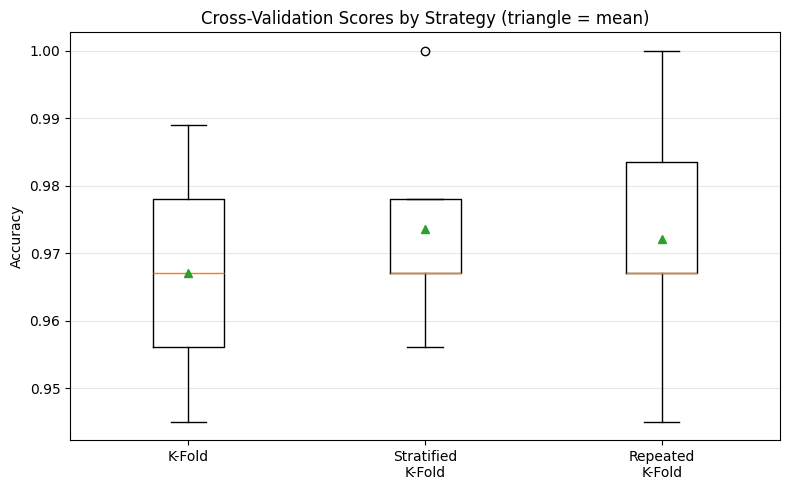

In [ ]:
# Plot 1: distribution of the scores for each strategy
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([kf_scores, skf_scores, rkf_scores], showmeans=True)
ax.set_xticklabels(["K-Fold", "Stratified\nK-Fold", "Repeated\nK-Fold"])
ax.set_ylabel("Accuracy")
ax.set_title("Cross-Validation Scores by Strategy (triangle = mean)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

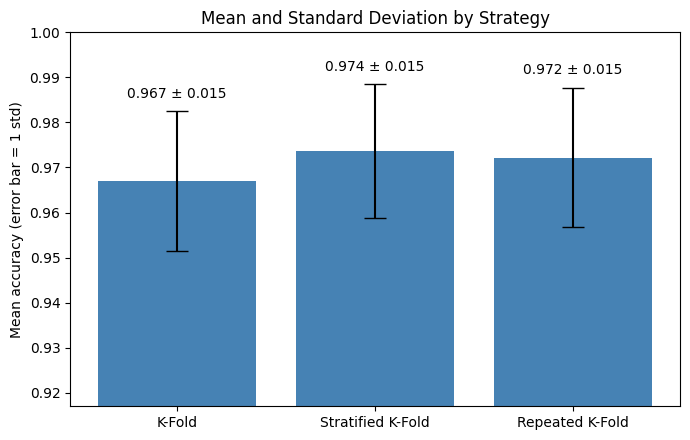

In [ ]:
# Plot 2: mean score with standard deviation as error bars
fig, ax = plt.subplots(figsize=(7, 4.5))
names = comparison.index
ax.bar(names, comparison["Mean"], yerr=comparison["Std"], capsize=8, color="steelblue")
lo = comparison["Mean"].min() - 0.05
ax.set_ylim(max(lo, 0), 1.0)
ax.set_ylabel("Mean accuracy (error bar = 1 std)")
ax.set_title("Mean and Standard Deviation by Strategy")
for i, (m, s) in enumerate(zip(comparison["Mean"], comparison["Std"])):
    ax.text(i, m + s + 0.003, f"{m:.3f} ± {s:.3f}", ha="center")
plt.tight_layout()
plt.show()

**How to read the comparison**
- **Mean** is the average validation performance. Similar means across strategies suggest the model's performance estimate is stable.
- **Standard deviation** shows how much the score changes from fold to fold. A smaller value means more consistent performance across different data splits.
- **Repeated K-Fold** produces more evaluations, so its mean is usually a more stable estimate than a single K-Fold run, even though the numbers themselves can be very close.
- Small differences between strategies on a dataset this clean are normal and may be within noise. The real benefit of each strategy is in reliability, not in a guaranteed higher score.

## Step 11: Why Stratified K-Fold Is Generally Preferred for Classification

Plain K-Fold splits at random, so by chance a fold can contain a noticeably different share of the positive class than the full dataset. Stratified K-Fold forces every fold to keep the same class ratio. The cells below show this directly.

In [ ]:
# Positive-class (malignant) share in each validation fold
def fold_ratios(cv):
    return [y_train.iloc[val_idx].mean() for _, val_idx in cv.split(X_train, y_train)]

ratio_table = pd.DataFrame({
    "K-Fold": fold_ratios(kf),
    "Stratified K-Fold": fold_ratios(skf),
}, index=[f"Fold {i}" for i in range(1, 6)]).round(4)

print("Overall positive share in training data:", round(y_train.mean(), 4))
print()
print(ratio_table)
print()
print("Spread (max - min) of positive share across folds:")
print("  K-Fold           :", round(ratio_table["K-Fold"].max() - ratio_table["K-Fold"].min(), 4))
print("  Stratified K-Fold:", round(ratio_table["Stratified K-Fold"].max() - ratio_table["Stratified K-Fold"].min(), 4))

Overall positive share in training data: 0.3736

        K-Fold  Stratified K-Fold
Fold 1  0.3516             0.3736
Fold 2  0.4286             0.3736
Fold 3  0.3297             0.3736
Fold 4  0.4176             0.3736
Fold 5  0.3407             0.3736

Spread (max - min) of positive share across folds:
  K-Fold           : 0.0989
  Stratified K-Fold: 0.0


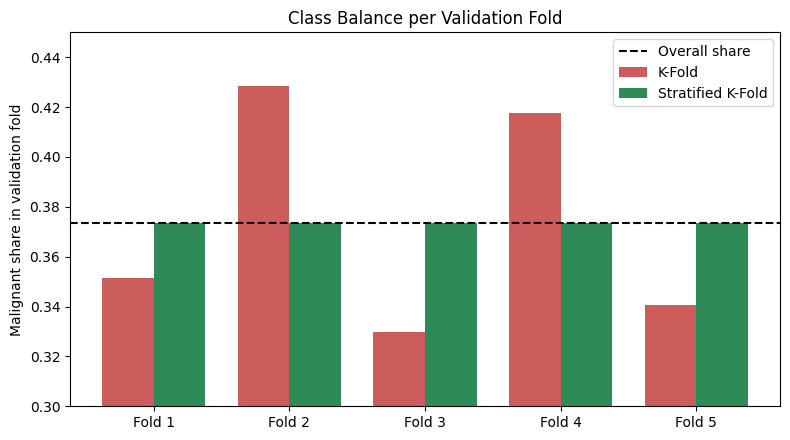

In [ ]:
# Plot 3: class ratio in each validation fold
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(5)
w = 0.38
ax.bar(x - w/2, ratio_table["K-Fold"], w, label="K-Fold", color="indianred")
ax.bar(x + w/2, ratio_table["Stratified K-Fold"], w, label="Stratified K-Fold", color="seagreen")
ax.axhline(y_train.mean(), color="black", linestyle="--", label="Overall share")
ax.set_xticks(x)
ax.set_xticklabels(ratio_table.index)
ax.set_ylim(0.3, 0.45)
ax.set_ylabel("Malignant share in validation fold")
ax.set_title("Class Balance per Validation Fold")
ax.legend()
plt.tight_layout()
plt.show()

**Why Stratified K-Fold is preferred for classification**
1. **Representative folds:** every validation fold has about the same class proportions as the whole dataset, so each fold is a fair mini-version of the real problem.
2. **More reliable scores:** with random splits, a fold may contain too few minority-class samples, which makes metrics such as precision, recall and F1 swing widely between folds.
3. **Essential for imbalanced data:** if the positive class is rare (for example 5%), plain K-Fold can produce a fold with almost no positives, or none at all. Metrics become undefined or misleading, while Stratified K-Fold guarantees positives in every fold.
4. **No extra cost:** it uses the same number of folds and the same training effort as K-Fold.

On this dataset (about 37% malignant) the imbalance is mild, so the difference is small. The advantage becomes much more important as the imbalance grows.

**Note:** Stratified K-Fold is for classification only. For regression there are no classes to preserve, so plain K-Fold is used.

## Step 12: LOOCV on a Small Dataset
Leave-One-Out CV uses a single sample as the validation set and all remaining samples for training, repeating this for every sample. For N samples it trains N models, so it is practical only for small datasets. Here we draw a small stratified sample of 100 rows from the training data.

In [ ]:
# Create a small dataset (100 samples) from the training data
X_small, _, y_small, _ = train_test_split(
    X_train, y_train, train_size=100, random_state=42, stratify=y_train
)
print("Small dataset size:", X_small.shape[0])
print("Malignant share   :", round(y_small.mean(), 3))

Small dataset size: 100
Malignant share   : 0.37


In [ ]:
loo = LeaveOneOut()
loo_scores = cross_val_score(model, X_small, y_small, cv=loo, scoring="accuracy")

print("Number of evaluations (models trained):", len(loo_scores))
print("Each score is 0 or 1 (one sample): unique values =", np.unique(loo_scores))
print("LOOCV accuracy (mean):", round(loo_scores.mean(), 4))
print("Samples misclassified:", int((loo_scores == 0).sum()), "out of", len(loo_scores))

Number of evaluations (models trained): 100
Each score is 0 or 1 (one sample): unique values = [0. 1.]
LOOCV accuracy (mean): 0.95
Samples misclassified: 5 out of 100


In [ ]:
# Compare LOOCV with 5-Fold and Stratified 5-Fold on the same small dataset
small_kf  = cross_val_score(model, X_small, y_small,
                            cv=KFold(5, shuffle=True, random_state=42), scoring="accuracy")
small_skf = cross_val_score(model, X_small, y_small,
                            cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="accuracy")

small_table = pd.DataFrame({
    "Models trained": [len(loo_scores), len(small_kf), len(small_skf)],
    "Mean accuracy":  [loo_scores.mean(), small_kf.mean(), small_skf.mean()],
}, index=["LOOCV", "K-Fold (5)", "Stratified K-Fold (5)"]).round(4)
print(small_table)

                       Models trained  Mean accuracy
LOOCV                             100           0.95
K-Fold (5)                          5           0.94
Stratified K-Fold (5)               5           0.94


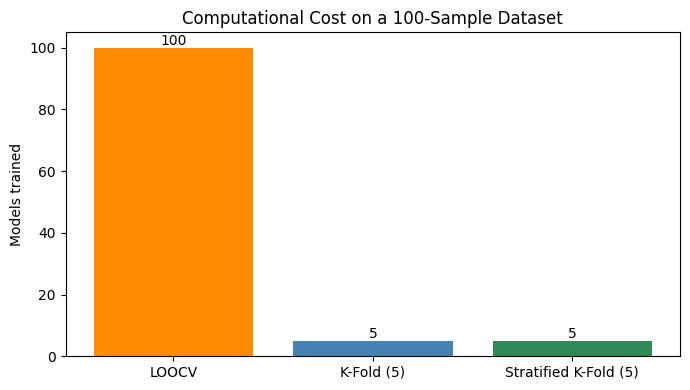

In [ ]:
# Plot 4: number of models trained, to show LOOCV cost
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(small_table.index, small_table["Models trained"], color=["darkorange", "steelblue", "seagreen"])
ax.set_ylabel("Models trained")
ax.set_title("Computational Cost on a 100-Sample Dataset")
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1, int(b.get_height()), ha="center")
plt.tight_layout()
plt.show()

**LOOCV summary**
- **Advantage:** uses almost all the data for training in every iteration (N-1 samples), and the result has no randomness because the splits are fixed. This is valuable when data is scarce.
- **Disadvantage:** it trains N models, so it becomes very slow for large datasets (for example 100,000 samples means 100,000 models). Its estimates can also have high variance, because the N training sets are almost identical.
- **When to use it:** small datasets (tens to a few hundred samples). For larger datasets, 5-fold or 10-fold (preferably stratified) is the practical choice.

## Overall Conclusion
- **K-Fold, Stratified K-Fold and Repeated K-Fold** gave similar mean accuracy, which indicates the model's performance is stable across different splits.
- **Repeated K-Fold** gives the most evaluations and therefore the most stable estimate of the mean.
- **Stratified K-Fold** is the default choice for classification because it keeps the class ratio equal in every fold, which matters even more with imbalanced data.
- **LOOCV** is a good choice only for small datasets because of its cost.